# 57. Decorrelation Scale Analysis Per Bay

This notebook calculates the decorrelation scale for each station, separated by basin.
The calculation logic follows the approach in `08_Decorrelation_Analysis_v3.ipynb`, `39a_Decorrelation_Analysis_Tokyo_Bay.py`, and `39b_Decorrelation_Analysis_Ise_Bay.py`.
The division logic follows `56_hypoxia_frequency_trend_v3.ipynb`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
from scipy.spatial.distance import cdist
from scipy.optimize import curve_fit
from scipy import stats
from pathlib import Path
import sys
import warnings

warnings.filterwarnings('ignore')

# Add project root to sys.path
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths
from utils.data_loader import load_and_process_data
from utils.mapping_config import MappingConfig

# Setup global mapping config
MappingConfig.apply_global_plot_styles()

In [2]:
print("Loading data...")
merged_gdf = load_and_process_data(force_reload=False)

TARGET_SEASON = 'Summer'
SAISUIPOIN_ID = 2
REPRESENTATIVE_MONTH = 8  # August

summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == TARGET_SEASON) & 
    (merged_gdf['saisuipoin'] == SAISUIPOIN_ID) &
    (merged_gdf['surveymont'] == REPRESENTATIVE_MONTH)
].copy()

summer_bottom_df['do_'] = pd.to_numeric(summer_bottom_df['do_'], errors='coerce')
summer_bottom_df = summer_bottom_df.dropna(subset=['do_'])

print(f"Total DO observations: {len(summer_bottom_df)}")

Loading data...
Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...
Total DO observations: 1419


In [3]:
# Define regions
sis_df = summer_bottom_df[summer_bottom_df['watermass_name'] == 'Seto Inland Sea']
sis_divisions = sis_df['division'].dropna().unique().tolist()

regions_info = []

regions_info.append({
    'name': 'Tokyo Bay',
    'data': summer_bottom_df[summer_bottom_df['watermass_name'] == 'Tokyo Bay'].copy()
})

regions_info.append({
    'name': 'Ise Bay',
    'data': summer_bottom_df[summer_bottom_df['watermass_name'] == 'Ise Bay'].copy()
})

for div in sis_divisions:
    regions_info.append({
        'name': div,
        'data': sis_df[sis_df['division'] == div].copy()
    })

print(f"Total regions defined: {len(regions_info)}")
for r in regions_info:
    print(f"{r['name']}: {len(r['data'])} observations")

Total regions defined: 14
Tokyo Bay: 1075 observations
Ise Bay: 33 observations
Osaka Bay: 20 observations
Harima Nada: 28 observations
Iyo Nada: 42 observations
Suo Nada: 62 observations
Bisan Seto: 18 observations
Bingo Nada: 19 observations
Bungo Channel: 36 observations
Hibiki Nada: 7 observations
Kii Channel: 23 observations
Aki Nada: 14 observations
Hiroshima Bay: 24 observations
Hiuchi Nada: 18 observations


In [4]:
# Parameters
min_periods = 15
r_crit_alpha = 0.01
distance_cutoff_km = 100

def gaussian_model_with_offset(x, A, dx):
    """Gaussian decay with offset, constrained: A + B = 1"""
    B = 1 - A
    return A * np.exp(-(x / dx)**2) + B

def calculate_r_crit(n, alpha=0.01):
    """Calculate critical correlation value for significance test.
    Uses t-distribution to find r_crit at given alpha level."""
    if n < 3:
        return 1.0
    df = n - 2
    t_crit = stats.t.ppf(1 - alpha/2, df)
    r_crit = np.sqrt(t_crit**2 / (t_crit**2 + df))
    return r_crit

def count_neighbors_within_distance(target_station, dist_matrix, max_distance_km=100):
    """Count number of stations within max_distance_km of target_station"""
    distances = dist_matrix.loc[target_station]
    neighbors = distances[(distances > 0) & (distances <= max_distance_km)]
    return len(neighbors)

In [5]:
all_results_list = []

for r_info in regions_info:
    region_name = r_info['name']
    region_data = r_info['data']
    print(f"\nProcessing {region_name}...")
    
    if len(region_data) == 0:
        print(f"No data for {region_name}. Skipping.")
        continue
        
    # Build yearly DO matrix (stations x years)
    yearly_do_df = region_data.groupby(['zettaicode', 'year'])['do_'].mean().unstack('year')
    
    # Filter stations with insufficient temporal data
    yearly_do_df = yearly_do_df[yearly_do_df.notna().sum(axis=1) >= min_periods]
    print(f"  Stations with >= {min_periods} valid years: {yearly_do_df.shape[0]}")
    
    if yearly_do_df.shape[0] < 2:
        print(f"Not enough stations for spatial decorrelation in {region_name}. Skipping.")
        continue
        
    # Get station coordinates
    station_coords = region_data[['zettaicode', 'geometry']].drop_duplicates('zettaicode')
    station_coords = station_coords[station_coords['zettaicode'].isin(yearly_do_df.index)]
    station_coords = station_coords.set_index('zettaicode')
    
    # Project to UTM Zone 53N (meter-based) for distance calculation
    stns_utm = gpd.GeoDataFrame(station_coords, geometry='geometry', crs=region_data.crs)
    stns_utm = stns_utm.to_crs(epsg=32653)
    
    # Calculate pairwise distance matrix in km
    coords = np.array([(geom.x, geom.y) for geom in stns_utm['geometry']])
    dist_matrix = cdist(coords, coords) / 1000.0
    dist_matrix_km = pd.DataFrame(dist_matrix, index=stns_utm.index, columns=stns_utm.index)
    
    # Calculate decorrelation scales
    for target_station in yearly_do_df.index:
        target_series = yearly_do_df.loc[target_station]
        correlations = yearly_do_df.corrwith(target_series, axis=1, drop=True)
        
        valid_stats = []
        for neighbor in yearly_do_df.index:
            neigh_series = yearly_do_df.loc[neighbor]
            valid_count = pd.concat([target_series, neigh_series], axis=1).dropna().shape[0]
            
            if valid_count >= min_periods:
                if neighbor == target_station:
                    corr_val = 1.0
                    dist_val = 0.0
                else:
                    corr_val = correlations[neighbor]
                    dist_val = dist_matrix_km.loc[target_station, neighbor]
                
                if not np.isnan(corr_val) and not np.isnan(dist_val):
                    if dist_val <= distance_cutoff_km:
                        valid_stats.append({'dist': dist_val, 'corr': corr_val, 'n': valid_count})
        
        df_fit = pd.DataFrame(valid_stats)
        
        if len(df_fit) < 5:
            continue
        
        x_data = df_fit['dist'].values
        y_data = df_fit['corr'].values
        
        try:
            # Fit Gaussian Model with offset (A + B = 1 constraint)
            popt, pcov = curve_fit(
                gaussian_model_with_offset, x_data, y_data,
                p0=[1.0, 50.0], bounds=([0, 0.001], [2.0, np.inf])
            )
            A_fit, dx_fit_param = popt
            B_fit = 1 - A_fit
            
            n_neighbors_100km = count_neighbors_within_distance(
                target_station, dist_matrix_km, max_distance_km=distance_cutoff_km
            )
            
            if n_neighbors_100km >= 2:
                r_crit = calculate_r_crit(n_neighbors_100km, alpha=r_crit_alpha)
            else:
                avg_n = df_fit['n'].mean()
                r_crit = calculate_r_crit(avg_n, alpha=r_crit_alpha)
            
            # Solve for decorrelation scale
            if A_fit > 0 and (r_crit - B_fit) / A_fit > 0:
                inner_val = (r_crit - B_fit) / A_fit
                if inner_val < 1:
                    decorrelation_scale = dx_fit_param * np.sqrt(-np.log(inner_val))
                else:
                    decorrelation_scale = 0.0
            else:
                decorrelation_scale = 0.0
            
            # R-squared
            residuals = y_data - gaussian_model_with_offset(x_data, *popt)
            ss_res = np.sum(residuals**2)
            ss_tot = np.sum((y_data - np.mean(y_data))**2)
            r_squared = 1 - (ss_res / ss_tot) if ss_tot != 0 else 0
            
            all_results_list.append({
                'Region': region_name,
                'Station_ID': target_station,
                'Decorrelation_Scale_km': decorrelation_scale,
                'Amplitude_A': A_fit,
                'Offset_B': B_fit,
                'dx_param': dx_fit_param,
                'R_squared': r_squared,
                'r_crit': r_crit,
                'n_neighbors_100km': n_neighbors_100km
            })
        except Exception as e:
            pass


Processing Tokyo Bay...
  Stations with >= 15 valid years: 28

Processing Ise Bay...
  Stations with >= 15 valid years: 0
Not enough stations for spatial decorrelation in Ise Bay. Skipping.

Processing Osaka Bay...
  Stations with >= 15 valid years: 0
Not enough stations for spatial decorrelation in Osaka Bay. Skipping.

Processing Harima Nada...
  Stations with >= 15 valid years: 0
Not enough stations for spatial decorrelation in Harima Nada. Skipping.

Processing Iyo Nada...
  Stations with >= 15 valid years: 0
Not enough stations for spatial decorrelation in Iyo Nada. Skipping.

Processing Suo Nada...
  Stations with >= 15 valid years: 0
Not enough stations for spatial decorrelation in Suo Nada. Skipping.

Processing Bisan Seto...
  Stations with >= 15 valid years: 0
Not enough stations for spatial decorrelation in Bisan Seto. Skipping.

Processing Bingo Nada...
  Stations with >= 15 valid years: 0
Not enough stations for spatial decorrelation in Bingo Nada. Skipping.

Processing B

In [6]:
results_df = pd.DataFrame(all_results_list)
print(f"\nTotal stations with fitted models across all regions: {len(results_df)}")
display(results_df.head())


Total stations with fitted models across all regions: 28


,Region,Station_ID,Decorrelation_Scale_km,Amplitude_A,Offset_B,dx_param,R_squared,r_crit,n_neighbors_100km
0,Tokyo Bay,00000122,8.765297,0.944892,0.055108,9.905373,0.544413,0.486932,27
1,Tokyo Bay,00000124,9.917781,0.893013,0.106987,10.728510,0.462267,0.486932,27
2,Tokyo Bay,00000125,7.750106,1.111897,-0.111897,9.851803,0.525911,0.486932,27
3,Tokyo Bay,00000128,12.047435,0.984411,0.015589,14.038496,0.491706,0.486932,27
4,Tokyo Bay,00000129,4.906583,0.774153,0.225847,4.706297,0.412388,0.486932,27


In [7]:
print(f"\n--- Decorrelation Scale Summary per Basin ---")
summary = results_df.groupby('Region').agg(
    Total_Stations=('Station_ID', 'count'),
    Non_Zero_Scale_Stations=('Decorrelation_Scale_km', lambda x: (x > 0).sum()),
    Mean_Scale_km=('Decorrelation_Scale_km', 'mean'),
    Median_Scale_km=('Decorrelation_Scale_km', 'median'),
    Max_Scale_km=('Decorrelation_Scale_km', 'max')
).reset_index()
display(summary)


--- Decorrelation Scale Summary per Basin ---


,Region,Total_Stations,Non_Zero_Scale_Stations,Mean_Scale_km,Median_Scale_km,Max_Scale_km
0,Tokyo Bay,28,28,5.740963,4.861708,12.885018


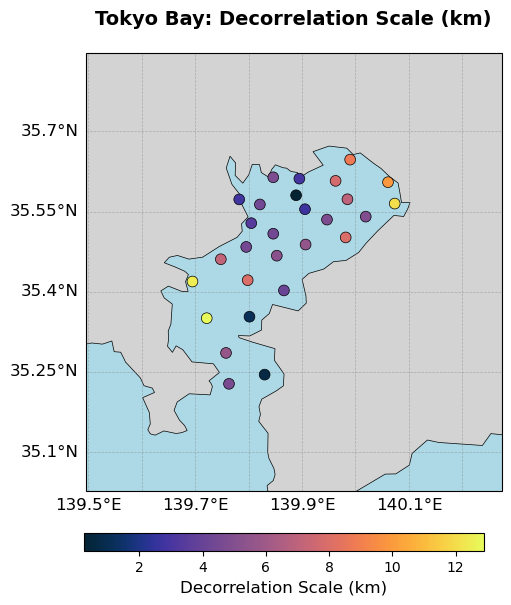

In [8]:
# Visualize on maps for each region
try:
    import xarray as xr
    gebco_path = ProjectPaths.BOUNDARIES_DIR / "gebco_2024_n35.5_s34.0_w139.0_e140.5.nc"
    gebco = xr.open_dataset(gebco_path)
    has_gebco = True
except:
    has_gebco = False

for region_name in results_df['Region'].unique():
    region_results = results_df[results_df['Region'] == region_name]
    region_data = pd.concat([r['data'] for r in regions_info if r['name'] == region_name])
    
    station_coords_wgs84 = region_data[['zettaicode', 'latitude', 'longitude']].drop_duplicates('zettaicode')
    plot_data = station_coords_wgs84.merge(region_results, left_on='zettaicode', right_on='Station_ID')
    
    if len(plot_data) == 0:
        continue
        
    bounds = region_data.total_bounds
    map_extent = [bounds[0] - 0.2, bounds[2] + 0.2, bounds[1] - 0.2, bounds[3] + 0.2]
    
    fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={'projection': ccrs.PlateCarree()})
    ax.set_facecolor(MappingConfig.COLOR_OCEAN)
    
    ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=MappingConfig.ZORDER_CARTOPY_LAND)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black', zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)
    
    if has_gebco and region_name == 'Tokyo Bay':
        bath = gebco['elevation'].values
        lons = gebco['lon'].values
        lats = gebco['lat'].values
        bath_masked = np.where(bath < 0, bath, np.nan)
        ax.pcolormesh(lons, lats, bath_masked, cmap=cmocean.cm.deep, 
                      transform=ccrs.PlateCarree(), zorder=0.1)
    
    sc = ax.scatter(
        plot_data['longitude'], plot_data['latitude'],
        c=plot_data['Decorrelation_Scale_km'],
        cmap=cmocean.cm.thermal,
        s=60, edgecolors='k', linewidths=0.5,
        transform=ccrs.PlateCarree(),
        zorder=MappingConfig.ZORDER_PREDICTED
    )
    
    gl = ax.gridlines(draw_labels=True, linestyle=MappingConfig.GRID_LINESTYLE,
                      color=MappingConfig.GRID_COLOR, alpha=MappingConfig.GRID_ALPHA,
                      linewidth=MappingConfig.GRID_LINEWIDTH, zorder=MappingConfig.ZORDER_GRIDLINES)
    gl.top_labels = False
    gl.right_labels = False
    
    ax.set_extent(map_extent, crs=ccrs.PlateCarree())
    plt.title(f'{region_name}: Decorrelation Scale (km)', pad=20, fontsize=14, fontweight='bold')
    
    plt.subplots_adjust(bottom=0.15)
    cbar_ax = fig.add_axes([0.25, 0.05, 0.5, 0.03])
    cbar = fig.colorbar(sc, cax=cbar_ax, orientation='horizontal')
    cbar.set_label('Decorrelation Scale (km)')
    
    plt.show()